In [589]:
from tokenizers import Tokenizer
import torch
import matplotlib.pyplot as plt

# Tokenizadores

In [590]:
tokenizador = Tokenizer.from_file("./data/tokenizer.json")
texto = "O gato dorme"

tokens = [5, 8, 2, 9, 4, 7]
context_size = 3
stride = 1

In [591]:
resultado = tokenizador.encode(texto)
# ['O', 'Ġga', 'to', 'Ġdor', 'me'] => Ġ representa espaço
print(resultado.tokens)
print(resultado.ids)

['O', 'Ġga', 'to', 'Ġdor', 'me']
[47, 4326, 287, 4956, 547]


In [592]:
texto_reconstruido = tokenizador.decode(resultado.ids)
print(texto_reconstruido)
print(texto_reconstruido == texto)

O gato dorme
True


# Ids

In [593]:
entrada = resultado.ids[:-1]
alvo = resultado.ids[1:]

print(entrada, alvo)

[47, 4326, 287, 4956] [4326, 287, 4956, 547]


# Stride

In [594]:
for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x = tokens[i: i + context_size]
    y = tokens[i + 1: i + context_size + 1]
    print(x, y)

i =  0
[5, 8, 2] [8, 2, 9]
i =  1
[8, 2, 9] [2, 9, 4]
i =  2
[2, 9, 4] [9, 4, 7]


# Tensores

In [595]:
x = []
y = []

for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x.append(tokens[i: i + context_size])
    y.append(tokens[i + 1: i + context_size + 1])
    print(x, y)
    
tensor_x = torch.tensor(x, dtype=torch.long)
tensor_y = torch.tensor(y, dtype=torch.long)
print(tensor_x, tensor_y)
print(tensor_x.shape)
print(tensor_y.shape)

i =  0
[[5, 8, 2]] [[8, 2, 9]]
i =  1
[[5, 8, 2], [8, 2, 9]] [[8, 2, 9], [2, 9, 4]]
i =  2
[[5, 8, 2], [8, 2, 9], [2, 9, 4]] [[8, 2, 9], [2, 9, 4], [9, 4, 7]]
tensor([[5, 8, 2],
        [8, 2, 9],
        [2, 9, 4]]) tensor([[8, 2, 9],
        [2, 9, 4],
        [9, 4, 7]])
torch.Size([3, 3])
torch.Size([3, 3])


# Batch

In [596]:
batch_size = 2


def batching(tensor_list, size=batch_size):
    batch = []
    for i in range(0, len(tensor_list), size):
        batch.append(tensor_list[i : i + size])

    return batch


batched_x = batching(tensor_x)
batched_y = batching(tensor_y)

print(batched_x, batched_y)
print(len(batched_x), len(batched_y))

[tensor([[5, 8, 2],
        [8, 2, 9]]), tensor([[2, 9, 4]])] [tensor([[8, 2, 9],
        [2, 9, 4]]), tensor([[9, 4, 7]])]
2 2


# Embeddings

In [597]:
num_embeddings = 10
num_dimensions = 4

embeddings = torch.nn.Embedding(num_embeddings, num_dimensions)

In [598]:
token_vectors = embeddings(batched_x[0])

print(token_vectors)
print("Tabela:", embeddings.weight.shape)
print("Entrada:", batched_x[0].shape)
print("Resultado:", token_vectors.shape)
print(embeddings.weight[8])

tensor([[[ 0.6301, -0.2805, -1.2528, -1.1576],
         [-0.7816, -0.2785, -1.5156, -0.3872],
         [ 0.8681, -0.7591,  0.6113, -0.3886]],

        [[-0.7816, -0.2785, -1.5156, -0.3872],
         [ 0.8681, -0.7591,  0.6113, -0.3886],
         [ 0.1751,  1.4907,  0.0072, -0.8138]]], grad_fn=<EmbeddingBackward0>)
Tabela: torch.Size([10, 4])
Entrada: torch.Size([2, 3])
Resultado: torch.Size([2, 3, 4])
tensor([-0.7816, -0.2785, -1.5156, -0.3872], grad_fn=<SelectBackward0>)


# Posição

In [599]:
num_linhas = 3
num_componentes = 4

posicao = torch.nn.Embedding(num_linhas, num_componentes)
value = torch.arange(num_linhas)

In [600]:
position_vectors = posicao(value)
print(position_vectors, position_vectors.shape)

tensor([[ 2.0513e-01, -6.7283e-01, -1.3494e-03, -4.0926e-01],
        [ 1.0637e+00, -8.5968e-02, -2.9845e-01, -2.3967e+00],
        [-2.2894e-01, -2.5343e+00, -8.3748e-01, -1.8895e-01]],
       grad_fn=<EmbeddingBackward0>) torch.Size([3, 4])


In [601]:
input_vectors = position_vectors + token_vectors
print(input_vectors, input_vectors.shape)
print("Tokens:", token_vectors)
print("Posições:", position_vectors)

tensor([[[ 0.8353, -0.9534, -1.2542, -1.5669],
         [ 0.2821, -0.3645, -1.8141, -2.7839],
         [ 0.6392, -3.2934, -0.2262, -0.5776]],

        [[-0.5764, -0.9513, -1.5170, -0.7965],
         [ 1.9318, -0.8451,  0.3128, -2.7853],
         [-0.0539, -1.0436, -0.8303, -1.0027]]], grad_fn=<AddBackward0>) torch.Size([2, 3, 4])
Tokens: tensor([[[ 0.6301, -0.2805, -1.2528, -1.1576],
         [-0.7816, -0.2785, -1.5156, -0.3872],
         [ 0.8681, -0.7591,  0.6113, -0.3886]],

        [[-0.7816, -0.2785, -1.5156, -0.3872],
         [ 0.8681, -0.7591,  0.6113, -0.3886],
         [ 0.1751,  1.4907,  0.0072, -0.8138]]], grad_fn=<EmbeddingBackward0>)
Posições: tensor([[ 2.0513e-01, -6.7283e-01, -1.3494e-03, -4.0926e-01],
        [ 1.0637e+00, -8.5968e-02, -2.9845e-01, -2.3967e+00],
        [-2.2894e-01, -2.5343e+00, -8.3748e-01, -1.8895e-01]],
       grad_fn=<EmbeddingBackward0>)


# Atenção

In [602]:
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

chamadas = []

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas
chamadas = []

print(queries, keys, values)

tensor([[[ 0.0630,  1.1686, -0.2329,  0.1968],
         [ 0.0052,  1.1659, -1.0268,  0.0669],
         [-0.5354,  1.6171,  0.7410,  0.1567]],

        [[-0.3645,  0.6114, -0.8179,  0.0148],
         [ 0.3550,  1.5195,  0.6536,  0.1587],
         [-0.2459,  0.7496, -0.3274,  0.0286]]], grad_fn=<UnsafeViewBackward0>) tensor([[[ 0.7150,  1.2321, -0.9617, -0.1612],
         [ 1.7418,  1.1457, -0.8014, -0.2762],
         [-0.0754,  2.0058, -1.4774,  0.3892]],

        [[ 1.0981,  0.3369,  0.0077,  0.0828],
         [ 0.2644,  2.3047, -2.1404, -0.2865],
         [ 0.7238,  0.7592, -0.4667,  0.0605]]], grad_fn=<UnsafeViewBackward0>) tensor([[[-0.1381,  0.2141, -1.4762,  0.0943],
         [-0.0764,  0.1256, -2.0823,  1.0385],
         [ 0.6970,  0.0686, -1.6294, -1.3587]],

        [[-0.1386, -0.2353, -1.5806,  0.1476],
         [ 0.6673,  0.6828, -0.9191,  0.2872],
         [ 0.1463, -0.0434, -1.2603,  0.0219]]], grad_fn=<UnsafeViewBackward0>)


In [603]:
resultado_produto_escalar = []
for i in range(3):
    resultado_produto_escalar.append(sum(queries[0, 1] * keys[0, i]))
    
tensor_pe = torch.stack(resultado_produto_escalar)
half_tensor_pe = tensor_pe/2
print(resultado_produto_escalar)
print(tensor_pe)
print(half_tensor_pe)


[tensor(2.4169, grad_fn=<AddBackward0>), tensor(2.1491, grad_fn=<AddBackward0>), tensor(3.8811, grad_fn=<AddBackward0>)]
tensor([2.4169, 2.1491, 3.8811], grad_fn=<StackBackward0>)
tensor([1.2084, 1.0745, 1.9406], grad_fn=<DivBackward0>)


In [604]:
mascara = half_tensor_pe.clone()
mascara[2] = float("-inf")
print(mascara)

tensor([1.2084, 1.0745,   -inf], grad_fn=<CopySlices>)


In [605]:
attention_weights = torch.softmax(mascara, dim=0)
print(attention_weights)
print(attention_weights.sum())

tensor([0.5334, 0.4666, 0.0000], grad_fn=<SoftmaxBackward0>)
tensor(1., grad_fn=<SumBackward0>)


In [606]:
weighted_vectors = []
for i in range(3):
    weighted_vectors.append(attention_weights[i]*values[0, i])
    
weighted_vectors = torch.stack(weighted_vectors)
print(weighted_vectors)
print(weighted_vectors.sum(dim=0))

tensor([[-0.0736,  0.1142, -0.7874,  0.0503],
        [-0.0357,  0.0586, -0.9716,  0.4845],
        [ 0.0000,  0.0000, -0.0000, -0.0000]], grad_fn=<StackBackward0>)
tensor([-0.1093,  0.1728, -1.7590,  0.5348], grad_fn=<SumBackward1>)


# Implementando atenção

In [607]:
chamadas = []
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas

In [608]:
# deprecated
def calcular_pontuacoes_test(queries, keys):
    save3 = []

    for i in range(len(queries)):
        save2 = []
        for j in range(len(queries[i])):
            save = []
            for k in range(len(queries[i])):
                save.append(sum(queries[i, j] * keys[i, k]) / 2)

            save2.append(torch.stack(save))

        save3.append(torch.stack(save2))

    return torch.stack(save3)

In [609]:
# New
def calcular_pontuacoes(queries, keys):
    dimensao = keys.shape[-1] ** 0.5
    transposed_keys = keys.transpose(-2, -1)
    return (queries @ transposed_keys) / dimensao

In [610]:
# deprecated
def sliding_mascara(tensors):
    mascaras = []
    for index in range(len(tensors)):
        print(tensors[index])
        mascara = tensors[index].clone()
        mascara[index + 1 : len(mascara)] = float("-inf")
        mascaras.append(mascara)

    return torch.stack(mascaras)

In [611]:
# new
def aplicar_mascara_causal(pontuacoes):
    pontuacoes_mascara = pontuacoes.clone()
    for exemplos_index in range(len(pontuacoes_mascara)):
        tokens_tamanho = len(pontuacoes_mascara[exemplos_index])
        for tokens_index in range(tokens_tamanho):
            pontuacoes_mascara[exemplos_index][tokens_index][tokens_index + 1 : tokens_tamanho] = float("-inf")

    return pontuacoes_mascara


In [612]:
def calcular_pesos(pontuacoes_mascaradas):
    return torch.softmax(pontuacoes_mascaradas, dim=-1)

In [613]:
def combinar_values(pesos, values):
    return pesos @ values

In [614]:
def atencao_causal(queries, keys, values):
    tensor_pe = calcular_pontuacoes(queries, keys)
    pontuacoes_mascaradas = aplicar_mascara_causal(tensor_pe)
    pesos = calcular_pesos(pontuacoes_mascaradas)
    contextos = combinar_values(pesos, values)
    return pesos, contextos

In [615]:
pesos, contextos = atencao_causal(queries, keys, values)

# Testes

In [616]:
test2 = pesos @ values
print(test2.shape)
print(torch.allclose(contextos, test2))

torch.Size([2, 3, 4])
True


# Validação se altera o futuro

In [617]:
queries_clone = queries.clone()
keys_clone = keys.clone()
values_clone = values.clone()

queries_clone[0][2] += 10
keys_clone[0][2] += 10
values_clone[0][2] += 10

In [618]:
pesos_clone, contexto_clone = atencao_causal(queries_clone, keys_clone, values_clone)
print(torch.allclose(contexto_clone[0][0], contextos[0][0]))
print(torch.allclose(contexto_clone[0][1], contextos[0][1]))


True
True


# Melhorando atencao

In [619]:
class AtencaoCausal(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada
        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )
        self.camada_linear_query = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_key = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_value = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )

    def forward(self, x):
        queries = self.camada_linear_query(x)
        keys = self.camada_linear_key(x)
        values = self.camada_linear_value(x)
        return atencao_causal(queries, keys, values)

In [620]:
atencao_cabeça_1 = AtencaoCausal(4, 2)
atencao_cabeça_2 = AtencaoCausal(4, 2)


In [621]:
peso_atencao_1, contexto_atencao_1 = atencao_cabeça_1(input_vectors)
print(peso_atencao_1, contexto_atencao_1)
peso_atencao_2, contexto_atencao_2 = atencao_cabeça_2(input_vectors)
print(peso_atencao_2, contexto_atencao_2)

tensor([[[1.0000, 0.0000, 0.0000],
         [0.4705, 0.5295, 0.0000],
         [0.2545, 0.3317, 0.4138]],

        [[1.0000, 0.0000, 0.0000],
         [0.1421, 0.8579, 0.0000],
         [0.2971, 0.4005, 0.3024]]], grad_fn=<SoftmaxBackward0>) tensor([[[ 0.7776, -0.4492],
         [ 1.1129, -0.5618],
         [ 0.3324, -0.6500]],

        [[ 0.3697, -0.7722],
         [ 0.6623, -0.0469],
         [ 0.4600, -0.3632]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[1.0000, 0.0000, 0.0000],
         [0.5059, 0.4941, 0.0000],
         [0.3628, 0.4429, 0.1943]],

        [[1.0000, 0.0000, 0.0000],
         [0.6968, 0.3032, 0.0000],
         [0.3380, 0.3298, 0.3322]]], grad_fn=<SoftmaxBackward0>) tensor([[[-0.1561, -0.1675],
         [ 0.0605, -0.3118],
         [-0.1387, -0.1698]],

        [[-0.2669, -0.3566],
         [-0.1182, -0.1306],
         [-0.0896, -0.0227]]], grad_fn=<UnsafeViewBackward0>)


In [622]:
contexto_cabecas = torch.cat(
    (contexto_atencao_1, contexto_atencao_2), dim=2
)

projecao_saida = torch.nn.Linear(4, 4, bias=False)
contexto_projetado = projecao_saida(contexto_cabecas)

print(contexto_projetado)
print(contexto_projetado.shape)

tensor([[[ 0.2680, -0.3127, -0.0888, -0.3673],
         [ 0.3996, -0.4109, -0.0241, -0.3824],
         [ 0.2507, -0.0186, -0.2114, -0.4113]],

        [[ 0.2073, -0.1060, -0.2154, -0.5251],
         [ 0.0961, -0.3873,  0.0664, -0.1411],
         [ 0.2282, -0.1159, -0.1204, -0.2637]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])


# Atenção de multiplas cabeças

In [623]:
class AtencaoMultiplasCabecas(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0, qtd_cabecas=1):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada

        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )

        if qtd_cabecas <= 0:
            raise ValueError(
                "A quantidade de cabeças precisa ser maior que zero."
            )

        if self.dimensao_saida % qtd_cabecas != 0:
            raise ValueError(
                "A dimensão de saída precisa ser divisível pela quantidade de cabeças."
            )

        self.qtd_cabecas = qtd_cabecas

        self.cabecas = torch.nn.ModuleList(
            [
                AtencaoCausal(
                    dimensao_entrada,
                    self.dimensao_saida // self.qtd_cabecas,
                )
                for _ in range(self.qtd_cabecas)
            ]
        )

        self.saida_linear = torch.nn.Linear(
            self.dimensao_saida,
            self.dimensao_saida,
            bias=False,
        )

    def forward(self, x):
        cabecas_atencao_contextos = []

        for index in range(len(self.cabecas)):
            cabecas_atencao_contextos.append(
                self.cabecas[index](x)[1]
            )

        cabecas_atencao = torch.cat(
            cabecas_atencao_contextos, dim=2
        )

        return self.saida_linear(cabecas_atencao)

In [624]:
multi_cabecas = AtencaoMultiplasCabecas(4, 4, 2)
saida_multi_cabecas = multi_cabecas(input_vectors)

print(saida_multi_cabecas)
print(saida_multi_cabecas.shape)

clone_input_vector = input_vectors.clone()
clone_input_vector[0, 2] += 10

saida_multi_cabecas_clone = multi_cabecas(clone_input_vector)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 0],
        saida_multi_cabecas[0, 0],
    )
)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 1],
        saida_multi_cabecas[0, 1],
    )
)

tensor([[[ 0.2498,  0.0055,  0.2570, -0.0286],
         [ 0.4500,  0.0104,  0.4512, -0.0651],
         [-0.1250, -0.0151,  0.1840,  0.0995]],

        [[ 0.0276,  0.1166,  0.4764, -0.1313],
         [ 0.1117,  0.0531,  0.3605, -0.0609],
         [ 0.1598, -0.0079,  0.2290,  0.0091]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])
True
True


# Normalização

In [625]:
saida_residual = input_vectors + saida_multi_cabecas

print(saida_residual)
print(saida_residual.shape)

tensor([[[ 1.0851, -0.9479, -0.9972, -1.5955],
         [ 0.7321, -0.3541, -1.3629, -2.8490],
         [ 0.5142, -3.3084, -0.0423, -0.4781]],

        [[-0.5489, -0.8348, -1.0406, -0.9278],
         [ 2.0435, -0.7919,  0.6733, -2.8462],
         [ 0.1059, -1.0515, -0.6013, -0.9936]]], grad_fn=<AddBackward0>)
torch.Size([2, 3, 4])


In [626]:
vetor_teste = torch.tensor([1.0, 3.0, 5.0, 7.0])

media = vetor_teste.mean()
var = vetor_teste.var(unbiased=False)
normalizacao = (vetor_teste - media) / (var + 1e-5) ** 0.5

print("Vetor: ", vetor_teste)
print("Média: ", media)
print("Variância: ", var)
print("Vetor normalizado: ", normalizacao)

Vetor:  tensor([1., 3., 5., 7.])
Média:  tensor(4.)
Variância:  tensor(5.)
Vetor normalizado:  tensor([-1.3416, -0.4472,  0.4472,  1.3416])


In [627]:
def normalizacao(vetor):
    media = vetor.mean(dim=2, keepdim=True)
    var = vetor.var(unbiased=False, dim=2, keepdim=True)
    normalizacao = (vetor - media) / (var + 1e-5) ** 0.5
    return normalizacao

In [628]:
print(normalizacao(saida_residual))

tensor([[[ 1.6764, -0.3296, -0.3782, -0.9686],
         [ 1.2815,  0.4581, -0.3066, -1.4331],
         [ 0.9109, -1.6820,  0.5334,  0.2378]],

        [[ 1.5871,  0.0179, -1.1121, -0.4929],
         [ 1.2543, -0.3098,  0.4985, -1.4430],
         [ 1.6055, -0.9021,  0.0733, -0.7767]]], grad_fn=<DivBackward0>)


# LayerNorm

In [629]:
class LayerNorm(torch.nn.Module):
    def __init__(self, qtd_componentes):
        super().__init__()
        self.qtd_componentes = qtd_componentes
        self.epsilon = 1e-5
        self.vetor_escala = torch.nn.Parameter(torch.ones(qtd_componentes))
        self.vetor_deslocamento = torch.nn.Parameter(torch.zeros(qtd_componentes))

    def forward(self, x):
        normalizado = self.normalizacao(x)
        resultado = self.vetor_escala * normalizado + self.vetor_deslocamento
        return resultado

    def normalizacao(self, vetor, eixo=-1):
        media = vetor.mean(dim=eixo, keepdim=True)
        var = vetor.var(unbiased=False, dim=eixo, keepdim=True)
        normalizacao = (vetor - media) / (var + self.epsilon) ** 0.5
        return normalizacao

In [630]:
layer = LayerNorm(4)
layer_saida_residual = layer(saida_residual)
print(layer_saida_residual)

tensor([[[ 1.6764, -0.3296, -0.3782, -0.9686],
         [ 1.2815,  0.4581, -0.3066, -1.4331],
         [ 0.9109, -1.6820,  0.5334,  0.2378]],

        [[ 1.5871,  0.0179, -1.1121, -0.4929],
         [ 1.2543, -0.3098,  0.4985, -1.4430],
         [ 1.6055, -0.9021,  0.0733, -0.7767]]], grad_fn=<AddBackward0>)


# MLP

In [631]:
class MLP(torch.nn.Module):
    def __init__(self, dimensao):
        super().__init__()
        self.dimensao = dimensao
        self.expansao = torch.nn.Linear(dimensao, 4 * dimensao)
        self.ativacao = torch.nn.GELU()
        self.projecao_saida = torch.nn.Linear(4 * dimensao, dimensao)

    def forward(self, x):
        expansao_vetor = self.expansao(x)
        ativacao_vetor = self.ativacao(expansao_vetor)
        projecao_saida_vetor = self.projecao_saida(ativacao_vetor)
        return projecao_saida_vetor

In [632]:
mlp = MLP(4)
mlp_saida_residual = mlp(layer_saida_residual)

In [633]:
conexao_residual_mlp = saida_residual + mlp_saida_residual

# print(layer_saida_residual)
# print(mlp_saida_residual)
print(conexao_residual_mlp)

tensor([[[ 1.1439, -0.7778, -1.0506, -1.8463],
         [ 0.7362, -0.1769, -1.3299, -2.9836],
         [ 0.7448, -3.1910, -0.1412, -0.8052]],

        [[-0.5409, -0.7038, -1.1667, -1.3926],
         [ 2.1048, -0.6351,  0.6980, -2.9203],
         [ 0.2237, -0.8924, -0.6770, -1.2274]]], grad_fn=<AddBackward0>)


In [634]:
class BlocoTransformer(torch.nn.Module):
    def __init__(self, dimensao, qtd_cabecas):
        super().__init__()
        self.norm_atencao = LayerNorm(dimensao)
        self.atencao = AtencaoMultiplasCabecas(dimensao,dimensao, qtd_cabecas)
        self.norm_mlp = LayerNorm(dimensao)
        self.mlp = MLP(dimensao)
        
    def forward(self, x):
        entrada = self.norm_atencao(x)
        entrada_normalizada = self.atencao(entrada)
        residual_atencao = x + entrada_normalizada
        residual_normalizada = self.norm_mlp(residual_atencao)
        saida_mlp = self.mlp(residual_normalizada)
        saida_bloco = residual_atencao + saida_mlp
        return saida_bloco

In [635]:
bloco_transformer = BlocoTransformer(4, 2)
saida_bloco = bloco_transformer(input_vectors)

In [636]:
camada_linear = torch.nn.Linear(4, 10, bias=False)
logits = camada_linear(saida_bloco)

In [637]:
print(torch.argmax(logits, dim=-1))
print(batched_y[0])

tensor([[3, 8, 3],
        [3, 3, 3]])
tensor([[8, 2, 9],
        [2, 9, 4]])


In [638]:
softmax_logits = torch.softmax(logits[0][0], dim=0)
log = -torch.log(softmax_logits[8])
print(log)

tensor(1.8774, grad_fn=<NegBackward0>)


In [639]:
save_error = []
choosen_batch = batched_y[0]
for i in range(len(choosen_batch)):
    save_error_example = []
    for j in range(len(choosen_batch[i])):
        softmax_logits = torch.softmax(logits[i][j], dim=0)
        save_error_example.append(-torch.log(softmax_logits[choosen_batch[i, j]]))

    save_error.append(torch.stack(save_error_example))

resultado = torch.stack(save_error)
print(resultado)
print(resultado.mean())

tensor([[1.8774, 3.4385, 1.8162],
        [3.1302, 2.9372, 2.8124]], grad_fn=<StackBackward0>)
tensor(2.6687, grad_fn=<MeanBackward0>)


In [640]:
logits_entropia = logits.reshape(-1, logits.shape[-1])
batch_entropia = batched_y[0].reshape(-1)
print(logits_entropia)
print(batch_entropia)

tensor([[-0.2133, -0.5230, -1.4842,  1.1046, -0.5895, -0.6395, -0.2056, -0.9608,
          0.3406, -0.1530],
        [-0.4376, -0.0432, -0.9746,  1.1049, -0.7834, -1.0597,  0.3973, -0.7926,
          1.2883, -0.9656],
        [ 1.3685, -1.1693, -2.7050,  2.1117, -0.2332,  0.3584, -0.6504, -1.1224,
         -0.3078,  1.1570],
        [ 0.4808, -0.4555, -0.6512,  0.7842,  0.1095, -0.1474,  0.3539, -0.6720,
          0.7482, -0.0625],
        [-0.5399,  0.3131, -2.9788,  2.2428, -2.3106, -0.9831, -1.1790, -0.3046,
         -0.3399, -0.2689],
        [ 0.4467, -0.2966, -1.2139,  1.1633, -0.3749, -0.1826, -0.0256, -0.5224,
          0.4154,  0.0369]], grad_fn=<ViewBackward0>)
tensor([8, 2, 9, 2, 9, 4])


In [641]:
erro = torch.nn.functional.cross_entropy(logits_entropia, batch_entropia)
erro.backward()

In [642]:
print(camada_linear.weight.grad)
print(camada_linear.weight.grad.shape)

tensor([[ 0.0676, -0.2432, -0.0337, -0.1701],
        [ 0.0630, -0.0904, -0.0204, -0.1392],
        [-0.0817,  0.3455,  0.3509,  0.6340],
        [ 0.4101, -0.6732, -0.0118, -0.7584],
        [-0.0175,  0.1841,  0.0157,  0.1573],
        [ 0.0358, -0.1106, -0.0199, -0.0903],
        [ 0.0454, -0.1138, -0.0554, -0.1478],
        [ 0.0361, -0.0632, -0.0131, -0.0827],
        [-0.1144,  0.0521,  0.0110,  0.0114],
        [-0.4444,  0.7129, -0.2233,  0.5859]])
torch.Size([10, 4])


In [643]:
sgd = torch.optim.SGD(camada_linear.parameters(), lr=0.1)
pesos_antes = camada_linear.weight.detach().clone()

sgd.step()

print(torch.allclose(pesos_antes, camada_linear.weight))

False


In [644]:
logits_2 = camada_linear(saida_bloco)
logits_entropia_2 = logits_2.reshape(-1, logits_2.shape[-1])
erro2 = torch.nn.functional.cross_entropy(logits_entropia_2, batch_entropia)

In [645]:
print(torch.allclose(erro, erro2))
print(erro, erro2)

False
tensor(2.6687, grad_fn=<NllLossBackward0>) tensor(2.3653, grad_fn=<NllLossBackward0>)


In [646]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, context_size, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(context_size, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [647]:
gpt = GptPequeno(10,3,4,2)
gpt_resultado = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado.shape)


tensor([[[ 0.6488, -0.2535, -0.7066,  0.6039,  0.5852, -0.3964, -0.1132,
          -0.1447, -0.5536, -0.7328],
         [-0.5905, -1.1208, -0.0599,  1.0656,  0.5908, -0.3948,  0.3376,
           1.1339,  0.7803, -0.1232],
         [ 0.8449,  0.2243, -0.4687, -0.0506,  0.2280, -0.3012, -0.1657,
          -0.4570, -0.9758, -0.5560]],

        [[ 0.6938,  0.2067, -0.9113,  0.5072,  0.4100,  0.0788, -0.3972,
          -0.8625, -0.3390, -0.6880],
         [ 0.2486, -0.8662, -0.4313,  0.8944,  0.7560, -0.7213,  0.2045,
           0.7242, -0.2625, -0.6216],
         [-0.5195,  0.5365,  0.4122, -0.5323, -0.5990,  0.6944, -0.1236,
          -0.4175,  0.6588,  0.6331]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 10])


In [648]:
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)
gpt_sgd.zero_grad()

In [649]:
gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
gpt_erro_save = gpt_erro.detach().clone()

In [650]:
gpt_erro.backward()
gpt_sgd.step()

In [651]:
print(gpt_erro, gpt_erro_save)

tensor(2.9840, grad_fn=<NllLossBackward0>) tensor(2.9840)


In [652]:
gpt_resultado_2 = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado_2)

tensor([[[ 0.6488, -0.2535, -0.7066,  0.6039,  0.5852, -0.3964, -0.1132,
          -0.1447, -0.5536, -0.7328],
         [-0.5905, -1.1208, -0.0599,  1.0656,  0.5908, -0.3948,  0.3376,
           1.1339,  0.7803, -0.1232],
         [ 0.8449,  0.2243, -0.4687, -0.0506,  0.2280, -0.3012, -0.1657,
          -0.4570, -0.9758, -0.5560]],

        [[ 0.6938,  0.2067, -0.9113,  0.5072,  0.4100,  0.0788, -0.3972,
          -0.8625, -0.3390, -0.6880],
         [ 0.2486, -0.8662, -0.4313,  0.8944,  0.7560, -0.7213,  0.2045,
           0.7242, -0.2625, -0.6216],
         [-0.5195,  0.5365,  0.4122, -0.5323, -0.5990,  0.6944, -0.1236,
          -0.4175,  0.6588,  0.6331]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[ 0.5828, -0.2550, -0.5972,  0.5237,  0.4579, -0.3884, -0.1034,
          -0.1490, -0.5076, -0.5764],
         [-0.6206, -1.0964,  0.0748,  0.9749,  0.5239, -0.3790,  0.3676,
           1.1435,  0.7470, -0.0558],
         [ 0.7786,  0.2112, -0.3739, -0.1372,  0.1121, -0.3169, -0.1373,
    

In [653]:
gpt_resultado_reshape_2 = gpt_resultado_2.reshape(-1, gpt_resultado_2.shape[-1])
gpt_erro_2 = torch.nn.functional.cross_entropy(gpt_resultado_reshape_2, batch_entropia)

In [654]:
print(gpt_erro_2, gpt_erro_save)

tensor(2.8400, grad_fn=<NllLossBackward0>) tensor(2.9840)


In [655]:
gpt = GptPequeno(10,3,4,2)
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)

In [656]:
for i in range(100):
    gpt_sgd.zero_grad()
    gpt_resultado = gpt(batched_x[0])
    gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
    gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
    gpt_erro.backward()
    gpt_sgd.step()
    
    if(i % 9 == 0):
        print(gpt_erro.item())

1.9326820373535156
1.2912057638168335
0.8923776149749756
0.6270827651023865
0.4235958755016327
0.2581119239330292
0.1601000428199768
0.10838670283555984
0.07938601821660995
0.06214694306254387
0.049301937222480774
0.04077128693461418


In [657]:
@torch.no_grad()
def gerar_tokens(modelo, sequencia_inicial, quantidade_novos_tokens, tamanho_contexto):
    sequencia = sequencia_inicial.detach().clone()
    print(sequencia)
    for i in range(quantidade_novos_tokens):
        contexto = sequencia[:, -tamanho_contexto: ]
        gpt_resultado = modelo(contexto)
        logits_ultima_posicao = gpt_resultado[:, -1, :]
        previsao = torch.argmax(logits_ultima_posicao, dim=-1, keepdim=True)
        sequencia = torch.cat((sequencia, previsao), dim=1)
        print(sequencia)
        
    return sequencia

In [658]:
gerar_tokens(gpt, batched_x[0][0:1], 3, 3)

tensor([[5, 8, 2]])
tensor([[5, 8, 2, 9]])
tensor([[5, 8, 2, 9, 4]])
tensor([[5, 8, 2, 9, 4, 9]])


tensor([[5, 8, 2, 9, 4, 9]])

In [659]:
def janela_contexto(ids, tamanho_contexto, passo=1):
    janela = [[], []]

    for i in range(0, len(ids) - tamanho_contexto, passo):
        janela[0].append(ids[i : i + tamanho_contexto])
        janela[1].append(ids[i + 1 : i + tamanho_contexto + 1])

    tensor_entradas_treino = torch.tensor(janela[0], dtype=torch.long)
    tensor_alvo_treino = torch.tensor(janela[1], dtype=torch.long)

    return (tensor_entradas_treino, tensor_alvo_treino)


def lotes_agrupamento(listagens, tamanho=1):
    lotes = []
    for i in range(0, len(listagens), tamanho):
        lotes.append(listagens[i : i + tamanho])

    return lotes

In [660]:
def ler_e_tokenizar(caminho_arquivo="./data/train.txt"):
    with open(file=caminho_arquivo, encoding="utf-8") as arquivo_treino:
        texto_treino = arquivo_treino.read(2000)
        return tokenizador.encode(texto_treino)

In [661]:
tokens_treino = ler_e_tokenizar()
ids_treino = tokens_treino.ids
    
entradas_treino, alvo_treino = janela_contexto(ids_treino, 32, 32)
loteamento_entradas_treino = lotes_agrupamento(entradas_treino, 4)
loteamento_alvo_treino = lotes_agrupamento(alvo_treino, 4)

In [662]:
tamanho_vocabulario = tokenizador.get_vocab_size()
tamanho_contexto = 32
dimensao = 32
qtd_cabecas = 4
gpt_corpus = GptPequeno(tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas)

In [663]:
print(gpt_corpus.embedding_tokens)
print(gpt_corpus.embedding_tokens.weight.shape)
print(loteamento_entradas_treino[0].shape)
print(loteamento_entradas_treino[0].dtype)
print(tokenizador.get_vocab_size())

Embedding(16000, 32)
torch.Size([16000, 32])
torch.Size([4, 32])
torch.int64
16000


In [664]:
primeiro_lote = gpt_corpus(loteamento_entradas_treino[0])
primeiro_lote = primeiro_lote.reshape(-1, primeiro_lote.shape[-1])
loteamento_reshaped = loteamento_alvo_treino[0].reshape(-1)
print(primeiro_lote.shape, loteamento_reshaped.shape)

torch.Size([128, 16000]) torch.Size([128])


In [665]:
corpus_erro = torch.nn.functional.cross_entropy(primeiro_lote, loteamento_reshaped)
gpt_corpus_sgd = torch.optim.SGD(gpt_corpus.parameters(), lr=0.1)
gpt_corpus_sgd.zero_grad()
corpus_erro.backward()
gpt_corpus_sgd.step()

In [666]:
logits_depois = gpt_corpus(loteamento_entradas_treino[0])
logits_depois = logits_depois.reshape(-1, logits_depois.shape[-1])
corpus_erro_2 = torch.nn.functional.cross_entropy(logits_depois, loteamento_reshaped)
print(corpus_erro, corpus_erro_2)

tensor(9.9284, grad_fn=<NllLossBackward0>) tensor(9.8962, grad_fn=<NllLossBackward0>)


In [667]:
def treinar_epoca(modelo, otimizador, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.train()
    
    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        otimizador.zero_grad()

        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        corpus_erro.backward()
        otimizador.step()

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()
        
    return soma_erros / total_tokens

In [668]:
tokens_validacao = ler_e_tokenizar("./data/val.txt")
ids_validacao = tokens_validacao.ids
    
entradas_validacao, alvo_validacao = janela_contexto(ids_validacao, 32, 32)
loteamento_entradas_validacao = lotes_agrupamento(entradas_validacao, 4)
loteamento_alvo_validacao = lotes_agrupamento(alvo_validacao, 4)

print(loteamento_entradas_validacao[0].shape, loteamento_alvo_validacao[0].shape)

torch.Size([4, 32]) torch.Size([4, 32])


In [669]:
@torch.no_grad()
def avaliar_epoca(modelo, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.eval()

    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()

    return soma_erros / total_tokens

In [670]:
historico_treino = []
historico_validacao = []
epocas_adicionais = 0

for i in range(10):
    print("Epoca: ", i + 1)
    historico_treino.append(
        treinar_epoca(
            gpt_corpus,
            gpt_corpus_sgd,
            loteamento_entradas_treino,
            loteamento_alvo_treino,
        )
    )
    epocas_adicionais += 1
    print("Erro médio treino: ", historico_treino[i])
    historico_validacao.append(
        avaliar_epoca(
            gpt_corpus, loteamento_entradas_validacao, loteamento_alvo_validacao
        )
    )
    print("Erro médio validação: ", historico_validacao[i])

Epoca:  1
Erro médio treino:  9.833393610440767
Erro médio validação:  9.829993629455567
Epoca:  2
Erro médio treino:  9.789890142587515
Erro médio validação:  9.824270820617675
Epoca:  3
Erro médio treino:  9.746880751389723
Erro médio validação:  9.818578656514486
Epoca:  4
Erro médio treino:  9.704082855811485
Erro médio validação:  9.812796592712402
Epoca:  5
Erro médio treino:  9.661216222322905
Erro médio validação:  9.806797981262207
Epoca:  6
Erro médio treino:  9.617997683011568
Erro médio validação:  9.800452041625977
Epoca:  7
Erro médio treino:  9.574134533221905
Erro médio validação:  9.793615531921386
Epoca:  8
Erro médio treino:  9.529318075913649
Erro médio validação:  9.78613084157308
Epoca:  9
Erro médio treino:  9.48321745945857
Erro médio validação:  9.77782096862793
Epoca:  10
Erro médio treino:  9.435473735515888
Erro médio validação:  9.768483670552571


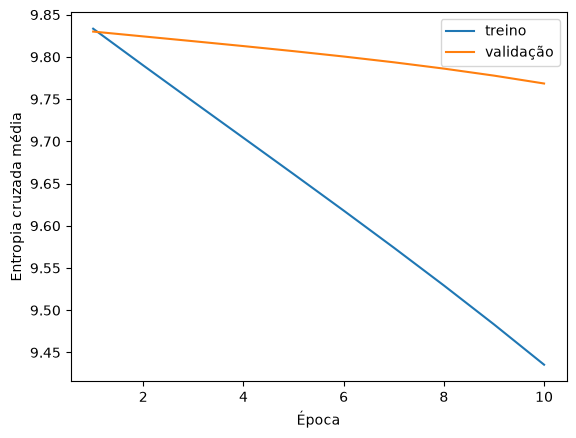

In [671]:
def grafico_historico(*historicos):
    for historico in historicos:
        plt.plot(list(range(1, len(historico[1]) + 1)), historico[1], label=historico[0])
                
    plt.xlabel("Época")
    plt.ylabel("Entropia cruzada média")
    plt.legend()
    plt.show()

grafico_historico(("treino", historico_treino), ("validação", historico_validacao))

In [672]:
configuracao = {
    "tamanho_vocabulario": 16000,
    "tamanho_contexto": 32,
    "dimensao": 32,
    "qtd_cabecas": 4,
}

In [673]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(tamanho_contexto, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [674]:
estado_modelo = gpt_corpus.state_dict()
estado_otimizador = gpt_corpus_sgd.state_dict()

In [675]:
checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [676]:
checkpoint_carregado = torch.load(
    "data/checkpoint_gpt_corpus.pt", map_location="cpu", weights_only=True
)

gpt_recuperado = GptPequeno(**checkpoint_carregado["configuracao"])
gpt_recuperado.load_state_dict(checkpoint_carregado["estado_modelo"])
epocas_adicionais = checkpoint_carregado["epocas_adicionais"]

In [677]:
gpt_corpus.eval()
gpt_recuperado.eval()
with torch.no_grad():
    print(
        torch.allclose(
            gpt_corpus(loteamento_entradas_validacao[0]),
            gpt_recuperado(loteamento_entradas_validacao[0]),
        )
    )

True


In [678]:
gpt_recuperado_sgd = torch.optim.SGD(gpt_recuperado.parameters(), lr=0.1)
gpt_recuperado_sgd.load_state_dict(checkpoint_carregado["estado_otimizador"])

In [679]:
erro_antes = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
treino = treinar_epoca(
    gpt_recuperado,
    gpt_recuperado_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
)
historico_treino.append(treino)
epocas_adicionais += 1
erro_depois = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
historico_validacao.append(erro_depois)

In [680]:
print("validação antes: ", erro_antes)
print("treino: ", treino)
print("validação depois: ", erro_depois)

validação antes:  9.768483670552571
treino:  9.385690248929537
validação depois:  9.757884407043457


In [681]:
estado_modelo = gpt_recuperado.state_dict()
estado_otimizador = gpt_recuperado_sgd.state_dict()

checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [682]:
checkpoint_carregado = torch.load(
    "data/checkpoint_gpt_corpus.pt", map_location="cpu", weights_only=True
)

historico_treino = checkpoint_carregado["historico"]["treino"]
historico_validacao = checkpoint_carregado["historico"]["validacao"]
epocas_adicionais = checkpoint_carregado["epocas_adicionais"]
gpt_recuperado = GptPequeno(**checkpoint_carregado["configuracao"])
gpt_recuperado.load_state_dict(checkpoint_carregado["estado_modelo"])
gpt_recuperado_sgd = torch.optim.SGD(gpt_recuperado.parameters(), lr=0.1)
gpt_recuperado_sgd.load_state_dict(checkpoint_carregado["estado_otimizador"])

In [683]:
erro_antes = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
treino = treinar_epoca(
    gpt_recuperado,
    gpt_recuperado_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
)
historico_treino.append(treino)
epocas_adicionais += 1
erro_depois = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
historico_validacao.append(erro_depois)

In [684]:
print("validação antes: ", erro_antes)
print("treino: ", treino)
print("validação depois: ", erro_depois)

validação antes:  9.757884407043457
treino:  9.333424641535832
validação depois:  9.745750427246094


In [685]:
estado_modelo = gpt_recuperado.state_dict()
estado_otimizador = gpt_recuperado_sgd.state_dict()

checkpoint = {
    "configuracao": checkpoint_carregado["configuracao"],
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [ ]:
def ciclo_epoca(
    modelo,
    otimizador,
    lotes_entrada_treino,
    lotes_alvo_treino,
    lotes_entrada_validacao,
    lotes_alvo_validacao,
    historico_treino,
    historico_validacao,
    qtd_epocas_executadas,
    qtd_epocas,
):
    epocas_adicionais = qtd_epocas_executadas
    posicao_historico_treino = len(historico_treino)
    posicao_historico_validacao = len(historico_validacao)
    for i in range(qtd_epocas):
        print("Epoca: ", qtd_epocas_executadas + i + 1)
        historico_treino.append(
            treinar_epoca(
                modelo,
                otimizador,
                lotes_entrada_treino,
                lotes_alvo_treino,
            )
        )
        epocas_adicionais += 1
        print("Erro médio treino: ", historico_treino[posicao_historico_treino + i])
        historico_validacao.append(
            avaliar_epoca(modelo, lotes_entrada_validacao, lotes_alvo_validacao)
        )
        print(
            "Erro médio validação: ",
            historico_validacao[posicao_historico_validacao + i],
        )

    return epocas_adicionais

In [688]:
def salvar_checkpoint(
    caminho,
    checkpoint_anterior,
    modelo,
    otimizador,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
):
    estado_modelo = modelo.state_dict()
    estado_otimizador = otimizador.state_dict()

    checkpoint = {
        "configuracao": checkpoint_anterior["configuracao"],
        "estado_modelo": estado_modelo,
        "estado_otimizador": estado_otimizador,
        "historico": {"treino": historico_treino, "validacao": historico_validacao},
        "epocas_adicionais": epocas_adicionais,
    }

    torch.save(checkpoint, caminho)

In [689]:
def carregar_checkpoint(caminho):
    try:
        checkpoint = torch.load(caminho, map_location="cpu", weights_only=True)
    except FileNotFoundError:
        checkpoint = {
            "configuracao": {},
            "estado_modelo": {},
            "estado_otimizador": {},
            "historico": {"treino": [], "validacao": []},
            "epocas_adicionais": 0,
        }

    return checkpoint

In [690]:
print(epocas_adicionais, len(historico_treino), len(historico_validacao))

epocas_adicionais = ciclo_epoca(
    gpt_corpus,
    gpt_corpus_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
    loteamento_entradas_validacao,
    loteamento_alvo_validacao,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
    1,
)

salvar_checkpoint(
    "data/checkpoint_gpt_corpus.pt",
    checkpoint,
    gpt_corpus,
    gpt_corpus_sgd,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
)

12 12 12
Epoca:  1
Erro médio treino:  9.385690248929537
Erro médio validação:  9.757884407043457


In [692]:
novo_checkpoint = carregar_checkpoint("data/checkpoint_gpt_corpus.pt")
print(novo_checkpoint["epocas_adicionais"])
print(len(novo_checkpoint["historico"]["treino"]))
print(len(novo_checkpoint["historico"]["validacao"]))

13
13
13
